> **Lösungsversion für Lehrkräfte.** Die Version für die Lernenden im Hauptordner wird daraus mit `python3 material/quelle/schuelerversion_erstellen.py` erzeugt: Code zwischen `# >>> LOESUNG` und `# <<< LOESUNG` wird entfernt, Zeilen mit `# | ` werden zum Platzhalter.

In [1]:
# Nur in der Lehrkraft-Version: Hilfsmodul aus dem übergeordneten Ordner finden
import sys
sys.path.insert(0, "..")

# 13 – Transfer Learning mit MobileNetV2

**Lernsituation „KI-Sichtprüfstation“ · Doppelstunde 8**

**Ziele – am Ende können Sie …**
- die Idee des Transfer Learning erklären,
- ein vortrainiertes Netz einfrieren und einen eigenen Kopf darauf trainieren,
- mit Grad-CAM prüfen, worauf das Netz bei seiner Entscheidung schaut,
- die Ergebnisse von FCNN, CNN und Transfer Learning vergleichen.

**So lesen Sie dieses Notebook**

| Kennzeichen | Bedeutung |
|---|---|
| **[Lesen]** | Grundlagen – lesen oder interaktiv ausprobieren |
| **[Aufgabe]** | Code ausführen, ergänzen oder selbst schreiben |
| **[Frage]** | Frage beantworten – schriftlich oder im Gespräch |
| **[Test]** | Teilzielkontrolle |
| **[Industrie]** | Bezug zur Fertigung |
| **[Raspberry Pi]** | Hinweis für den Raspberry Pi |

## [Lesen] Die Idee
![Transfer Learning](../material/bilder/transfer_learning.svg)

**MobileNetV2** ist ein CNN für Smartphones und kleine Rechner. Es wurde mit *ImageNet* trainiert (1,4 Millionen Fotos, 1000 Klassen). Seine Faltungsschichten erkennen bereits Kanten, Ecken, Rundungen und Formen – das hilft auch bei unseren Symbolen und bei Bauteilen.

Wir nehmen MobileNetV2 **ohne** seine letzte Schicht (`include_top=False`), **frieren es ein** und setzen einen **eigenen, kleinen Kopf** für unsere Klassen darauf. Nur dieser Kopf wird trainiert.

[Raspberry Pi] Beim **ersten** Ausführen werden die vortrainierten Gewichte (etwa 9 MB) aus dem Internet geladen und in `~/.keras/models` gespeichert.

In [2]:
# Werkzeuge laden – diese Zelle einfach ausführen (Umschalt + Enter)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import ki_hilfen as kh

ORDNER = kh.ORDNER          # Ordner mit Notebooks, Datensätzen und Modellen

import keras
from keras import layers

kh.setze_seed(42)

DATENSATZ = "dataset"
GROESSE = 224              # MobileNetV2 ist für 224 x 224 Pixel vortrainiert
FARBE = "rgb"              # MobileNetV2 braucht Farbbilder
BATCH = 32
LERNRATE = 0.001

X, y, klassen = kh.lade_datensatz(DATENSATZ, GROESSE, FARBE)
X_train, X_val, X_test, y_train, y_val, y_test = kh.teile_datensatz(X, y)
ANZAHL_KLASSEN = len(klassen)
print("Training:", len(X_train), " Validierung:", len(X_val), " Test:", len(X_test))

augmentierung = keras.Sequential([      # wie im Original-Notebook 02c – nur beim Training aktiv
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
])
train_ds = kh.als_tf_dataset(X_train, y_train, BATCH, mischen=True)
val_ds = kh.als_tf_dataset(X_val, y_val, BATCH)
test_ds = kh.als_tf_dataset(X_test, y_test, BATCH)

Aus Zwischenspeicher geladen: 1735 Bilder
Training: 1214  Validierung: 260  Test: 261


## 1 · Das vortrainierte Basisnetz laden und einfrieren

In [3]:
basis = keras.applications.MobileNetV2(
    input_shape=(GROESSE, GROESSE, 3),
    include_top=False,          # ohne die ImageNet-Ausgabeschicht
    weights="imagenet",         # vortrainierte Gewichte
)
basis.trainable = False         # einfrieren: diese Gewichte werden nicht verändert

print("Schichten im Basisnetz:", len(basis.layers))
print("Gewichte im Basisnetz:", basis.count_params())

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Schichten im Basisnetz: 154
Gewichte im Basisnetz: 2257984


## 2 · [Aufgabe 1] Den eigenen Kopf bauen
Das Gesamtmodell entsteht Schritt für Schritt. Vorgegeben sind Eingang, Augmentierung, Vorverarbeitung und Basisnetz. Ergänzen Sie den Kopf:
1. `layers.GlobalAveragePooling2D()` – macht aus jeder der 1280 Merkmalskarten eine Zahl,
2. `layers.Dropout(0.2)`,
3. `layers.Dense(ANZAHL_KLASSEN, activation="softmax")`.

Jede Schicht wird auf das vorige Ergebnis angewendet: `x = schicht(x)`.

In [4]:
pooling = layers.GlobalAveragePooling2D()
dropout = layers.Dropout(0.2)
ausgabe = layers.Dense(ANZAHL_KLASSEN, activation="softmax")

eingang = keras.Input(shape=(GROESSE, GROESSE, 3))
x = augmentierung(eingang)                           # nur beim Training aktiv
x = layers.Rescaling(1 / 127.5, offset=-1)(x)        # 0 ... 255  ->  -1 ... +1 (wie preprocess_input)
x = basis(x, training=False)                         # Basisnetz bleibt im Vorhersage-Modus
# >>> LOESUNG
# | # TODO: x durch pooling, dropout und ausgabe schicken
x = pooling(x)
x = dropout(x)
x = ausgabe(x)
# <<< LOESUNG
modell = keras.Model(eingang, x)
modell.summary()

kh.pruefe_gleich(modell.output_shape, (None, ANZAHL_KLASSEN), "Ausgabe des Modells")
kh.pruefe_gleich(sum(w.numpy().size for w in modell.trainable_weights), 1280 * ANZAHL_KLASSEN + ANZAHL_KLASSEN,
                 "trainierbare Gewichte (nur der Kopf)")

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

True

### [Frage]
Das Basisnetz hat über 2 Millionen Gewichte, der Kopf nur gut 5 000. Warum reichen deshalb wenige Epochen und wenige Bilder?

## 3 · Den Kopf trainieren
Die Lernrate wird mit `ExponentialDecay` nach und nach kleiner. EarlyStopping beendet das Training, wenn sich 10 Epochen lang nichts verbessert.

[Raspberry Pi] Eine Epoche dauert auf dem Raspberry Pi 5 etwa 1 bis 2 Minuten.

Training läuft ...
Epoch 1/10
38/38 - 29s - 762ms/step - accuracy: 0.5329 - loss: 1.0982 - val_accuracy: 0.7308 - val_loss: 0.7137
Epoch 2/10
38/38 - 19s - 487ms/step - accuracy: 0.7578 - loss: 0.6218 - val_accuracy: 0.7846 - val_loss: 0.5804
Epoch 3/10
38/38 - 21s - 555ms/step - accuracy: 0.8130 - loss: 0.5035 - val_accuracy: 0.8115 - val_loss: 0.5102
Epoch 4/10
38/38 - 55s - 1s/step - accuracy: 0.8427 - loss: 0.4455 - val_accuracy: 0.8308 - val_loss: 0.4805
Epoch 5/10
38/38 - 29s - 769ms/step - accuracy: 0.8542 - loss: 0.4075 - val_accuracy: 0.8423 - val_loss: 0.4446
Epoch 6/10
38/38 - 30s - 786ms/step - accuracy: 0.8624 - loss: 0.3933 - val_accuracy: 0.8462 - val_loss: 0.4332
Epoch 7/10
38/38 - 26s - 692ms/step - accuracy: 0.8526 - loss: 0.3878 - val_accuracy: 0.8500 - val_loss: 0.4350
Epoch 8/10
38/38 - 22s - 576ms/step - accuracy: 0.8871 - loss: 0.3157 - val_accuracy: 0.8385 - val_loss: 0.4043
Epoch 9/10
38/38 - 16s - 422ms/step - accuracy: 0.8855 - loss: 0.3271 - val_accuracy: 0.

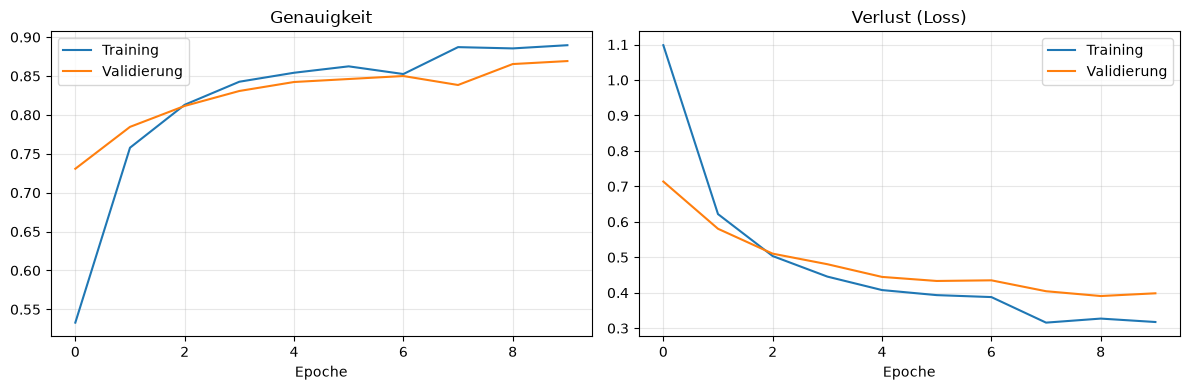

In [5]:
EPOCHEN = 10                  # Original-Einstellung; mit mehr Zeit: 50

lernplan = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=LERNRATE, decay_steps=500, decay_rate=0.96, staircase=True)
modell.compile(optimizer=keras.optimizers.Adam(lernplan),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])

bestes = kh.modellpfad("transfer_bestes.weights.h5")
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10),
    keras.callbacks.ModelCheckpoint(bestes, monitor="val_loss",
                                    save_best_only=True, save_weights_only=True),
]
print("Training läuft ...")
verlauf = modell.fit(train_ds, validation_data=val_ds, epochs=EPOCHEN,
                     callbacks=callbacks, verbose=2)
modell.load_weights(bestes)
kh.zeige_lernkurven(verlauf)

Test-Genauigkeit Transfer Learning: 85.4 %


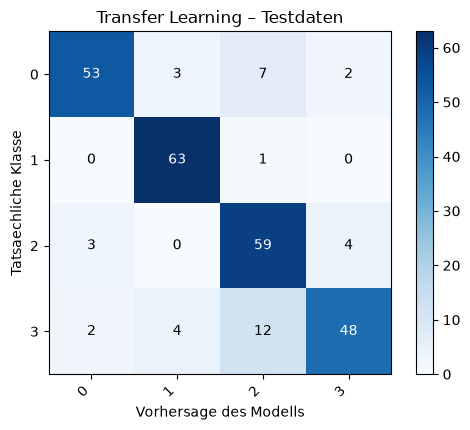

              precision    recall  f1-score   support

           0      0.914     0.815     0.862        65
           1      0.900     0.984     0.940        64
           2      0.747     0.894     0.814        66
           3      0.889     0.727     0.800        66

    accuracy                          0.854       261
   macro avg      0.862     0.855     0.854       261
weighted avg      0.862     0.854     0.853       261



array([[53,  3,  7,  2],
       [ 0, 63,  1,  0],
       [ 3,  0, 59,  4],
       [ 2,  4, 12, 48]])

In [6]:
_, test_acc = modell.evaluate(test_ds, verbose=0)
print("Test-Genauigkeit Transfer Learning:", round(test_acc * 100, 1), "%")

y_pred = modell.predict(X_test, verbose=0).argmax(axis=1)
kh.zeige_konfusionsmatrix(y_test, y_pred, klassen, titel="Transfer Learning – Testdaten")

## 4 · [Lesen] Grad-CAM: Worauf schaut das Netz?
Eine hohe Genauigkeit heißt noch nicht, dass das Netz das **Richtige** gelernt hat. Grad-CAM färbt die Bildbereiche ein, die die Entscheidung am stärksten beeinflusst haben (rot = wichtig).

[Industrie] Typischer Fehler aus der Praxis: Ein Modell erkennt „fehlerhaft“ zuverlässig – aber nur, weil alle Fehlerbilder an einem anderen Tag mit anderem Licht aufgenommen wurden. Grad-CAM deckt so etwas auf.

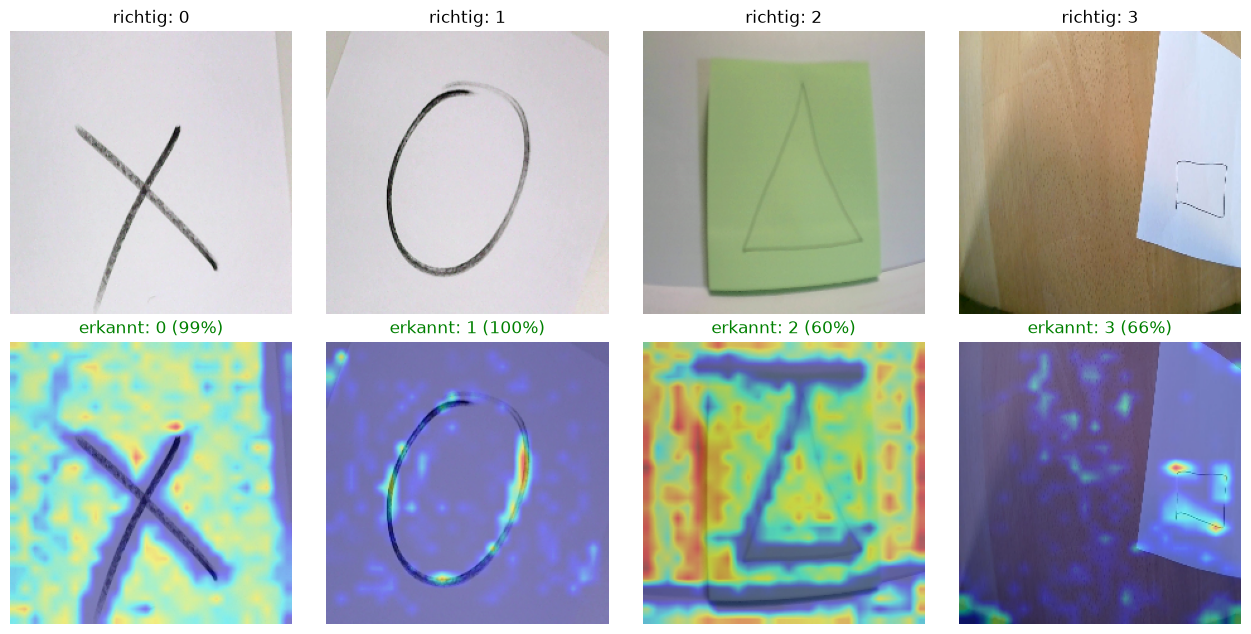

In [7]:
kh.zeige_gradcam(modell, basis, [pooling, dropout, ausgabe], X_test, y_test, klassen,
                 schicht="block_6_expand")

### [Frage]
Schaut das Netz auf das Symbol oder auf etwas anderes (Papierrand, Tisch, Schatten)? Was würden Sie an der Aufnahme ändern, wenn das Netz auf den Hintergrund achtet?

## 5 · Zusatz: Feinabstimmung (Fine-Tuning)
Beim Fine-Tuning werden die oberen Schichten des Basisnetzes (ab Schicht 100) wieder freigegeben und mit **kleiner Lernrate** weitertrainiert. Das kann noch einige Prozentpunkte bringen.

[Raspberry Pi] Jetzt läuft das Training durch einen großen Teil des Netzes – eine Epoche dauert mehrere Minuten. Setzen Sie `FEINABSTIMMUNG = True`, wenn Sie Zeit haben.

In [8]:
FEINABSTIMMUNG = False
AB_SCHICHT = 100
EPOCHEN_FEIN = 10             # Original-Einstellung; mit mehr Zeit: 100

if FEINABSTIMMUNG:
    basis.trainable = True
    for schicht in basis.layers[:AB_SCHICHT]:
        schicht.trainable = False
    lernplan_fein = keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=LERNRATE / 10, decay_steps=500, decay_rate=0.96, staircase=True)
    modell.compile(optimizer=keras.optimizers.RMSprop(lernplan_fein),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    verlauf_fein = modell.fit(train_ds, validation_data=val_ds, epochs=EPOCHEN_FEIN,
                              callbacks=callbacks, verbose=2)
    modell.load_weights(bestes)
    kh.zeige_lernkurven(verlauf, verlauf_fein, markierung=len(verlauf.epoch) - 1)
    _, test_acc = modell.evaluate(test_ds, verbose=0)
    print("Test-Genauigkeit nach Feinabstimmung:", round(test_acc * 100, 1), "%")

## 6 · Speichern

In [9]:
kh.speichere_modell(modell, "transfer", klassen, GROESSE, FARBE,
                    test_genauigkeit=round(float(test_acc), 4), datensatz=DATENSATZ)

INFO:tensorflow:Assets written to: C:\Users\METZGE~1\AppData\Local\Temp\tmptcsrzfx9\assets


INFO:tensorflow:Assets written to: C:\Users\METZGE~1\AppData\Local\Temp\tmptcsrzfx9\assets


Saved artifact at 'C:\Users\METZGE~1\AppData\Local\Temp\tmptcsrzfx9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  3153986229008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004286496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004287696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004287216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004288896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004288656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004287936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004286736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004290336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3153004288416: TensorSpec(shape=(), dtype=tf.resource, name=None)


{'name': 'transfer',
 'klassen': ['0', '1', '2', '3'],
 'groesse': 224,
 'farbe': 'rgb',
 'keras': 'transfer.keras',
 'erstellt': '2026-11-25 17:25',
 'test_genauigkeit': 0.8544,
 'datensatz': 'dataset',
 'tflite': 'transfer.tflite'}

### [Aufgabe 2] Die drei Ansätze vergleichen
Tragen Sie Ihre Ergebnisse ein. Die Rechenzeit pro Bild auf dem Raspberry Pi messen Sie in Notebook 20.

| Modell | Bild | Gewichte | Test-Genauigkeit | Trainingszeit |
|---|---|---|---|---|
| FCNN (11) | 32 × 32 grau | | | |
| CNN (12) | 224 × 224 RGB | | | |
| Transfer (13) | 224 × 224 RGB | | | |

Welches Modell würden Sie für die Prüfstation wählen – und warum?

In [10]:
kh.ram_aufraeumen()